In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras.layers import Conv2D, UpSampling2D, Dropout
from keras.layers import BatchNormalization
from keras.models import Sequential
from keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing.image import img_to_array, load_img
from skimage.color import rgb2lab, lab2rgb
from skimage.transform import resize
from skimage.io import imsave
from keras.models import Sequential
from tensorflow.keras import regularizers
np.random.seed(42)
tf.random.set_seed(42)

In [ ]:
path = 'C:/Training Dataset 8'

#Normalize images - divide by 255
#Because here we use ReLu, as ReLu uses values between 0 and 1
# random_seed = 42
train_datagen = ImageDataGenerator(rescale=1. / 255)

#Resize images, if needed
train = train_datagen.flow_from_directory(path, 
                                          target_size=(256, 256), 
                                          batch_size=64, 
                                          class_mode=None,
                                          seed=42
                                          )

X =[]
Y =[]


# Iterate over the batches
for batch in train:
    for img in batch:  # Process each image in the current batch
        lab = rgb2lab(img)
        X.append(lab[:, :, 0])
        Y.append(lab[:, :, 1:] / 128)  # Normalize AB channels

    if len(X) >= 346:  # Assuming 346 is the total number of images
        break  # Stop after processing all images

# Convert lists to NumPy arrays and reshape
X = np.array(X).reshape(-1, 256, 256, 1)
Y = np.array(Y)


print(X.shape)
print(Y.shape)

Found 346 images belonging to 1 classes.
(346, 256, 256, 1)
(346, 256, 256, 2)


In [15]:
from tensorflow.keras.layers import Conv2D, Conv2DTranspose, LeakyReLU, BatchNormalization, Dense, Flatten, Input, Concatenate, RepeatVector, Reshape
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Define the encoder network
input_img = Input(shape=(256, 256, 1))
x = input_img
filters = [64, 128, 128, 256, 256, 512, 512, 256]
for i, f in enumerate(filters):
    x = Conv2D(f, (3, 3), padding='same', strides=2 if i % 2 == 0 else 1)(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(alpha=0.2)(x)

# Feature extraction
global_features = Flatten()(x)
global_features = Dense(1024, activation='relu')(global_features)
global_features = Dense(512, activation='relu')(global_features)
global_features = Dense(256, activation='relu')(global_features)

# Fusion
fusion = RepeatVector(16 * 16)(global_features)  # Adjusted to the output shape of the last conv layer
fusion = Reshape((16, 16, 256))(fusion)
fusion = Concatenate()([x, fusion])

# Decoder network
x = fusion
for f in [256, 128, 64, 32]:
    x = Conv2DTranspose(f, (3, 3), strides=2, padding='same')(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(alpha=0.2)(x)

output = Conv2D(2, (3, 3), activation='tanh', padding='same')(x)

# Define and compile the model
model = Model(inputs=input_img, outputs=output)
model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['accuracy'])

# Model summary
model.summary()


Model: "model_2"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_4 (InputLayer)        [(None, 256, 256, 1)]        0         []                            
                                                                                                  
 conv2d_26 (Conv2D)          (None, 128, 128, 64)         640       ['input_4[0][0]']             
                                                                                                  
 batch_normalization_32 (Ba  (None, 128, 128, 64)         256       ['conv2d_26[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 leaky_re_lu_32 (LeakyReLU)  (None, 128, 128, 64)         0         ['batch_normalization_32

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, TensorBoard
import os
import datetime

# Directory for TensorBoard log files
log_dir = os.path.join("logs", "fit", datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
tensorboard_callback = TensorBoard(log_dir=log_dir, histogram_freq=1)

# Model checkpoint to save the best model
checkpoint_callback = ModelCheckpoint(
    'C:/Code10_best_model.h5', 
    monitor='val_loss', 
    save_best_only=True, 
    verbose=1
)

# Early stopping to halt the training when validation loss does not improve
early_stopping_callback = EarlyStopping(
    monitor='val_loss', 
    patience=20, 
    verbose=1,
    restore_best_weights=True
)

# Reduce learning rate when a metric has stopped improving
reduce_lr_callback = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.2, 
    patience=5, 
    verbose=1,
    min_delta=0.0001, 
    cooldown=0, 
    min_lr=0
)

# Fitting the model with callbacks
history = model.fit(
    X, Y, 
    validation_split=0.1, 
    epochs=200, 
    batch_size=64,
    callbacks=[checkpoint_callback, early_stopping_callback, reduce_lr_callback, tensorboard_callback]
)

# Save the final model - consider if necessary since the best model is saved via checkpoint
model.save('C:/Code10.model')


Epoch 1/200
5/5 [==============================] - ETA: 0s - loss: 0.1812 - accuracy: 0.5743
Epoch 1: val_loss improved from inf to 1.01864, saving model to C:/Users/iaka416/Documents/VS Code/MSc Code\Code10_best_model.h5
5/5 [==============================] - 71s 16s/step - loss: 0.1812 - accuracy: 0.5743 - val_loss: 1.0186 - val_accuracy: 0.4300 - lr: 0.0010
Epoch 2/200
5/5 [==============================] - ETA: 0s - loss: 0.0603 - accuracy: 0.6128
Epoch 2: val_loss improved from 1.01864 to 1.00547, saving model to C:/Users/iaka416/Documents/VS Code/MSc Code\Code10_best_model.h5
5/5 [==============================] - 94s 9s/step - loss: 0.0603 - accuracy: 0.6128 - val_loss: 1.0055 - val_accuracy: 0.4546 - lr: 0.0010
Epoch 3/200
5/5 [==============================] - ETA: 0s - loss: 0.0475 - accuracy: 0.6164
Epoch 3: val_loss did not improve from 1.00547
5/5 [==============================] - 36s 6s/step - loss: 0.0475 - accuracy: 0.6164 - val_loss: 1.0356 - val_accuracy: 0.4272 - lr

INFO:tensorflow:Assets written to: C:/Users/iaka416/Documents/VS Code/MSc Code/Code10.model\assets


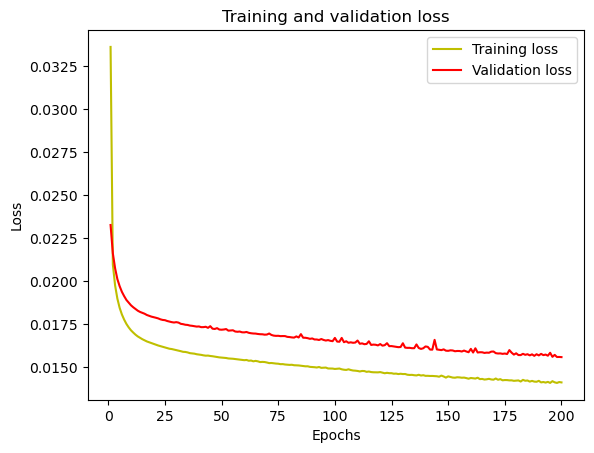

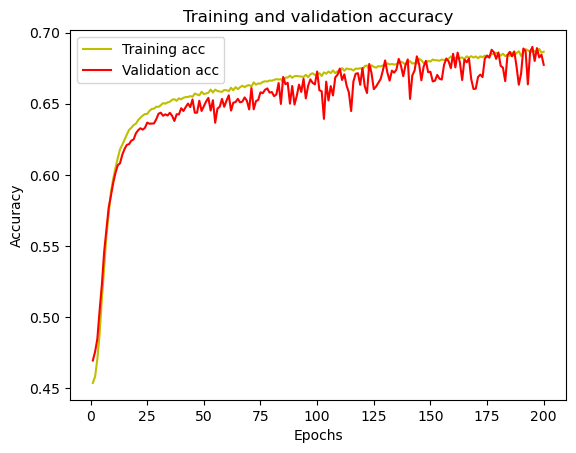

39/39 [==============================] - 23s 580ms/step


In [13]:
#plot the training and validation accuracy and loss at each epoch
from matplotlib import pyplot as plt
import seaborn as sns
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, 'y', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
plt.plot(epochs, acc, 'y', label='Training acc')
plt.plot(epochs, val_acc, 'r', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Predicting the Test set results
y_pred = model.predict(X)
y_pred = (y_pred > 0.5)

